### JSON file structure


```json
{
      "ConfigName-date...": {
            "attributes": {
                  ...,
                  "repetition": "N",
                  ...,
            },
            "itervars": {
                  "K": "<value>",
                  "p": "<value>"
            },
            "config": [
                  ...
            ],
            "scalars": [
                  {
                        "module" : "HighwayBarrier.barrier.stdLane[0]",
                        "name" : "ResponseTime_Stat:mean",
                        "value" : 62.573952090742,
                        "attributes" : {
                              "recordingmode" : "mean",
                              "source" : "ResponseTime"
                        }
                  },
                  ...
            ],
            "vectors": {
                  ...
            }
      },
      ...
}

### Imports

In [322]:
import os
import json
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict
from scipy.stats import sem, t, norm

### Files and constants

Files must be exported as follows:
1. In OMNeT++, open the .anf file of the configuration
2. Go to the scalars page
3. Select **everything**
4. Export in JSON format
5. Name the file with this format:
      - ***[distribution type]_[workload type].json***, where:
      - [distribution type] = `"Exp"` / `"Log"`
      - [workload type] = `"High"` / `"Medium"` / `"Low"`
6. Save the files in the jsonFiles folder (next to this notebook)

In [323]:
dir_path = 'jsonFiles/'

# Distribution type
DIST_EXPONENTIAL = "Exp"
DIST_LOGNORMAL = "Log"

# Workload type
WORKLOAD_HIGH = "High"
WORKLOAD_MEDIUM = "Medium"
WORKLOAD_LOW = "Low"
WORKLOAD_HIGH_24_LANES = "High_N24"
WORKLOAD_HIGH_100_LANES = "High_N100"

# Modules
STD_LANE_0 = "HighwayBarrier.barrier.stdLane[0]"
ETC_LANE_0 = "HighwayBarrier.barrier.etcLane[0]"

# Constants
MEAN_SERVICE_TIME_STD_LANE = "**.barrier.stdLane[*].mean"


SHOW_GRAPHS = True
SAVE_GRAPH_FILES = True


In [324]:
def printModuleName(isStd, index):
      if isStd:
            return f"HighwayBarrier.barrier.stdLane[{index}]"
      else:
            return f"HighwayBarrier.barrier.etcLane[{index}]"

## Functions

### ConfidenceInterval function

In [325]:
def ConfidenceInterval(data, level):
      '''
            data:       array di campioni
            level:      confidence interval level (es: 95% -> 0.95)
      '''
      mean = np.mean(data)
      std_dev = np.std(data, ddof=1)
      n = len(data)
      z = norm.ppf(1 - (1 - level) / 2)

      interval = z * (std_dev / np.sqrt(n))

      return interval

### CollectScalars function
Scans the given JSON file and returns a dictionary, indexed by (K, p), of the values of the requested statistic

In [326]:
def CollectScalars(dist_type, workload, module_name, stat_name):
      '''
            dist_type:  distribution type (use preset)
            workload:   workload type (use preset)
            module_name:      module name, es: HighwayBarrier.barrier.stdLane[0]
            stat_name:  statistic name
      '''

      # Dictionary
      data_dict = defaultdict(lambda: defaultdict(list))

      # Create file path
      file_path = os.path.join(dir_path, f"{dist_type}_{workload}.json")

      # Open json file
      with open(file_path, 'r') as file:
            data = json.load(file)

      # Loop over all entries
      for config_name, entry in data.items():

            # Extract the values of p and K
            itervars = entry.get("itervars", {})
            p = float(itervars.get("p", 0))
            K = int(itervars.get("K", 0))

            scalars = entry.get("scalars", [])
            # Iterate over the scalars
            for scalar in scalars:

                  # Check that this is the requested module and statistic
                  if    scalar.get("module") == module_name and \
                        scalar.get("attributes", {}).get("source") == stat_name:

                        # Get the value
                        scalar_value = scalar.get("value")

                        # TODO
                        # Skip if out of bound

                        # Group by (K, p)
                        data_dict[K][p].append(scalar_value)

      return data_dict


### GetParamaterValue function

In [327]:
def GetParamaterValue(dist_type, workload, paramater_name):
      '''
            dist_type:  distribution type (use preset)
            workload:   workload type (use preset)
            paramater_name: es: "**.barrier.stdLane[*].mean"
      '''

      # Create file path
      file_path = os.path.join(dir_path, f"{dist_type}_{workload}.json")

      # Open json file
      with open(file_path, 'r') as file:
            data = json.load(file)

      paramater_value = None

      for key, entry in data.items():
            for config_entry in entry["config"]:
                  if paramater_name in config_entry:
                        # Extract the numeric value
                        paramater_value = config_entry[paramater_name]
                        break
                  
            if paramater_value is not None:
                  return paramater_value

### PlotData function
For each (K, p) pair, plots the mean value with its confidence interval 

In [328]:
def PlotData(plot_ref, data_dict, color_maps, line_style='solid', marker_type='o', exclusions=None, ci_lines_threshold = 1.75, label_text='K='):
      '''
            plot_ref:   plot reference
            data_dict:  data dictionary
            color_maps: color mapping for each K value
            line_style:
                  'solid'     linea continua
                  'dashed'    linea tratteggiata
                  'dashdot'   tratto-punto
                  'dotted'    linea puntinata
            exclusions: set of (K, p) tuples to exclude from the analysis
      '''

      if exclusions is None:
            exclusions = set()
      
      for K in sorted(data_dict.keys()):  # For each K, in order
            p_values = sorted(data_dict[K].keys())  # Sort the values of p
            mean_values = []

            for p in p_values:
                  
                  # Skip the (K, p) pair if it is listed in exclusions
                  if (K, p) in exclusions:
                        continue

                  values = data_dict[K][p]
                  if values:
                        # Compute the mean of the values
                        mean_value = np.mean(values)

                        # Compute the confidence interval of the values
                        ci = ConfidenceInterval(values, 0.95)

                        # Check whether the CI is above the threshold
                        if ci > ci_lines_threshold:
                              # Draw error bars only if the CI is significant
                              plot_ref.errorbar(
                                    p,  # X value
                                    mean_value,  # Y value
                                    yerr=ci,
                                    fmt='',  # Marker type ('o' = circle)
                                    color=color_maps[K],
                                    ecolor=color_maps[K],
                                    capsize=5
                              )
                        
                        # Store the mean points for the interpolation
                        mean_values.append(mean_value)

            # Add the linear interpolation
            if p_values:
                  # Filter p_values to drop the excluded pairs
                  filtered_p_values = [p for p in p_values if (K, p) not in exclusions]
                  plot_ref.plot(
                        filtered_p_values, 
                        mean_values, 
                        color=color_maps[K], 
                        linestyle=line_style, 
                        linewidth=0.75,
                        marker=marker_type,
                        label=f'{label_text}{K}'
                  )




In [329]:
def GroupScalarsByConfigurationParameter(file_name, module_name, stat_source, group_by_config):
      """
            Extracts data filtered by module and statistic, and returns it grouped by the field specified in group_by.

            Args:
                  file_name   (str): The file name.
                  module_name (str): The module name.
                  stat_source (str): The value of attributes->source.
                  group_by_config:   The configuration field used to group the values

            Returns:
            dict: A map from {group_by_config} (distinct value) to arrays of values of the statistic.
      """

      # Create file path
      file_path = os.path.join(dir_path, f"{file_name}.json")

      # Open json file
      with open(file_path, 'r') as file:
            data = json.load(file)

      # Dictionary
      data_dict = defaultdict(list)

      for key, content in data.items():

            # Look up the value directly in the list of configuration parameters
            group_param = None
            for param in content.get("config", []):
                  if group_by_config in param:
                        group_param = param[group_by_config]
                        break

            group_param = deleteUnitOfMeasurement(group_by_config, group_param)

            # Check whether scalars exist and filter by module and source
            for scalar in content.get("scalars", []):
                  if scalar["module"] == module_name and scalar["attributes"].get("source") == stat_source:
                        data_dict[group_param].append(scalar["value"])

      return data_dict

# Plots

#### Waiting times of Std lanes and ETC lanes

In [330]:
def PlotDataAllLanes(plot_ref, data_dict, color_maps, line_style='solid', marker_type='o', exclusions=None, ci_lines_threshold = 1.75):
      '''
            plot_ref:   plot reference
            data_dict:  data dictionary
            color_maps: color mapping for each K value
            line_style:
                  'solid'     linea continua
                  'dashed'    linea tratteggiata
                  'dashdot'   tratto-punto
                  'dotted'    linea puntinata
            exclusions: set of (K, p) tuples to exclude from the analysis
      '''

      if exclusions is None:
            exclusions = set()
      
      for K in sorted(data_dict.keys()):  # For each K, in order
            p_values = sorted(data_dict[K].keys())  # Sort the values of p
            mean_values = []

            for p in p_values:

                  values = data_dict[K][p]
                  if values:
                        # Compute the mean of the values
                        mean_value = np.mean(values)

                        # Compute the confidence interval of the values
                        ci = ConfidenceInterval(values, 0.95)

                        # Check whether the CI is above the threshold
                        if ci > ci_lines_threshold:
                              # Draw error bars only if the CI is significant
                              plot_ref.errorbar(
                                    p,  # X value
                                    mean_value,  # Y value
                                    yerr=ci,
                                    fmt='',  # Marker type ('o' = circle)
                                    color=color_maps[K],
                                    ecolor=color_maps[K],
                                    capsize=5
                              )
                        
                        # Store the mean points for the interpolation
                        mean_values.append(mean_value)

            # Add the linear interpolation
            if p_values:
                  # Filter p_values to drop the excluded pairs
                  filtered_p_values = [p for p in p_values if (K, p) not in exclusions]
                  plot_ref.plot(
                        filtered_p_values, 
                        mean_values, 
                        color=color_maps[K], 
                        linestyle=line_style, 
                        linewidth=0.75,
                        marker=marker_type,
                        label=f'Lane {K}'
                  )

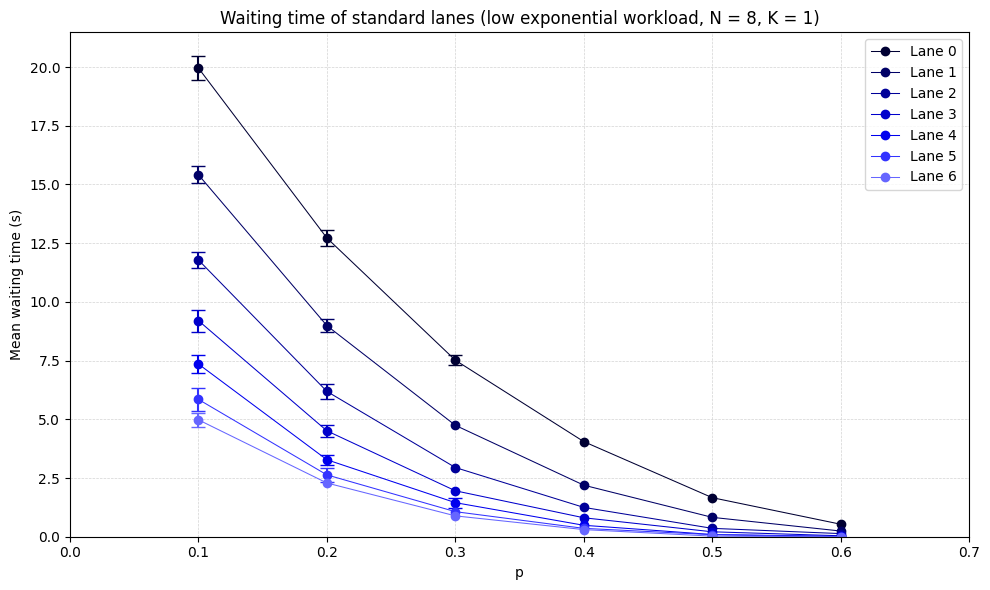

In [331]:
stdLanes = {}

for i in range(9):
    
    # Function call
    data_dict = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_LOW, printModuleName(True, i), 'WaitingTime')

    # Filter for K=1
    filtered_data = data_dict.get(1, {})

    # Add the filtered data to the final dictionary
    stdLanes[i] = filtered_data

plt.figure(figsize=(10, 6))

color_map = {
    0: '#000033',  # Very dark blue
    1: '#000066',  # Dark blue
    2: '#000099',  # Intermediate blue
    3: '#0000CC',  # Medium-dark blue
    4: '#0000EE',  # Medium blue
    5: '#3333FF',  # Medium-bright blue
    6: '#6666FF',  # Brighter medium blue
}

# Add the plots
PlotDataAllLanes(plt, stdLanes, color_map, 'solid', "o", exclusions=None, ci_lines_threshold=0.2)


# Chart configuration
plt.xlabel("p")
plt.ylabel("Mean waiting time (s)")
plt.title("Waiting time of standard lanes (low exponential workload, N = 8, K = 1)")


# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0)  # Y axis starts at 0
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
plt.legend(loc='upper right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'allStdLanes'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()
      


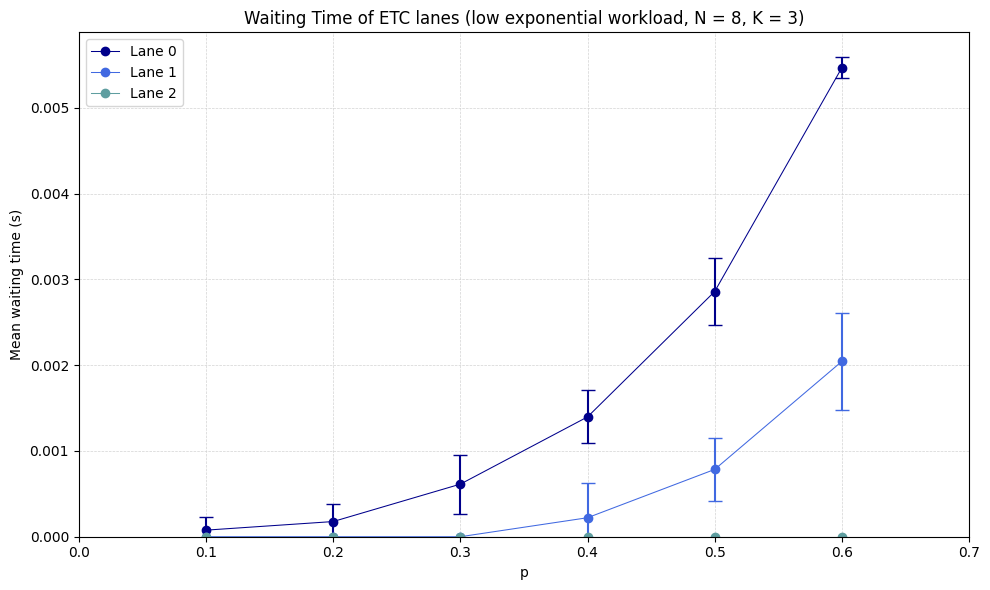

In [332]:
etcLanes = {}

for i in range(3):
    
    # Function call
    data_dict = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_LOW, printModuleName(False, i), 'WaitingTime')

    # Filter for K=2
    filtered_data = data_dict.get(3, {})

    # Add the filtered data to the final dictionary
    etcLanes[i] = filtered_data

plt.figure(figsize=(10, 6))

color_map = {
      0: '#00008B',  # Dark blue
      1: '#4169E1',  # Royal blue
      2: '#5F9EA0',  # Dark teal
}

# Add the plots
PlotDataAllLanes(plt, etcLanes, color_map, 'solid', "o", exclusions=None, ci_lines_threshold=0)


# Chart configuration
plt.xlabel("p")
plt.ylabel("Mean waiting time (s)")
plt.title("Waiting Time of ETC lanes (low exponential workload, N = 8, K = 3)")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0)  # Y axis starts at 0
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
plt.legend(loc='upper left')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'allEtcLanes'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()




## Exponential distribution

### Low workload

In [333]:
# Plot the times of both standard lane 0 and ETC lane 0

stdl_res = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_LOW, STD_LANE_0, 'ResponseTime')
stdl_wai = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_LOW, STD_LANE_0, 'WaitingTime')

mean_service_time = GetParamaterValue(DIST_EXPONENTIAL, WORKLOAD_LOW, MEAN_SERVICE_TIME_STD_LANE)
if mean_service_time.endswith('s'):
      mean_service_time = float(mean_service_time[:-1])

etcl_res = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_LOW, ETC_LANE_0, 'ResponseTime')
etcl_wai = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_LOW, ETC_LANE_0, 'WaitingTime')

# Colors for each K
color_map = {
    0: 'blue',
    1: 'green',
    2: 'orange',
    3: 'red'      
}


#### Response time

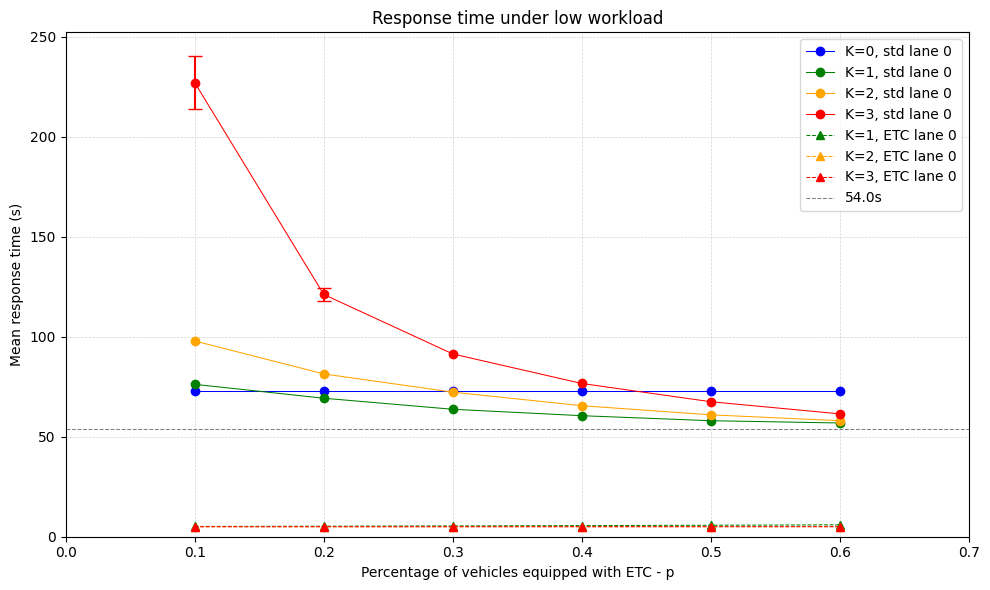

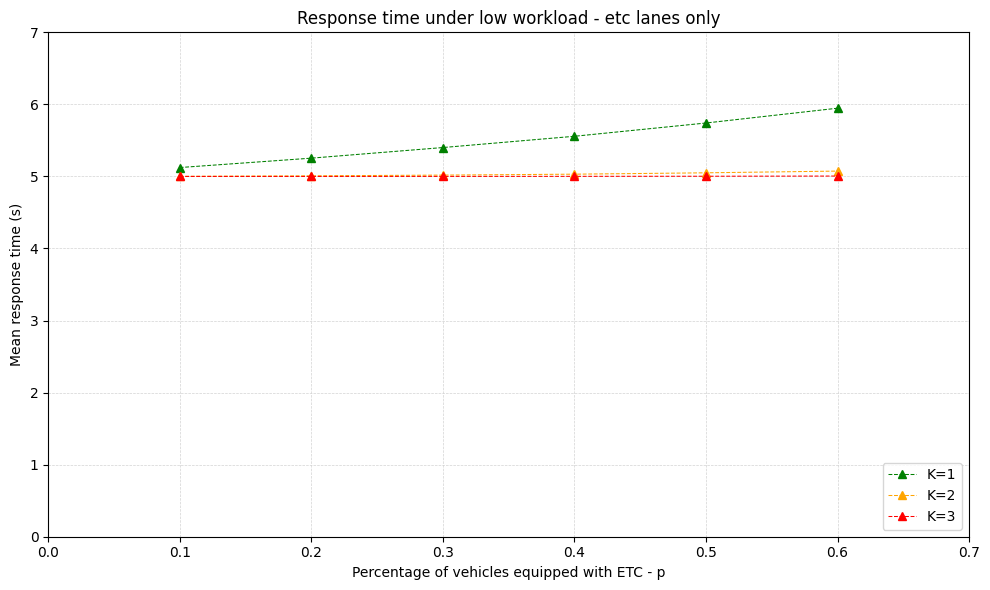

In [334]:
plt.figure(figsize=(10, 6))

# Add the plots
PlotData(plt, stdl_res, color_map, 'solid', "o")
PlotData(plt, etcl_res, color_map, 'dashed', "^")

# Horizontal line for the mean service time of the standard lanes
plt.axhline(y=mean_service_time, color='grey', linestyle='--', linewidth = 0.75, label=f"{mean_service_time}s")

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean response time (s)")
plt.title("Response time under low workload")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0)  # Y axis starts at 0
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
handles, labels = plt.gca().get_legend_handles_labels()
label_count = {}
for i in range(len(labels)-1):
      label = labels[i]
      
      if label not in label_count: label_count[label] = 1
      else: label_count[label] += 1
      
      # Append std or etc
      if label_count[label] == 1: labels[i] = f'{label}, std lane 0'
      else: labels[i] = f'{label}, ETC lane 0'
plt.legend(handles, labels, loc='upper right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_lowWorkload_response'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


## ETC lane only

plt.figure(figsize=(10, 6))

# Add the plots
PlotData(plt, etcl_res, color_map, 'dashed', "^")

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean response time (s)")
plt.title("Response time under low workload - etc lanes only")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0, 7)  # Set the Y-axis range
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
plt.legend(loc='lower right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_lowWorkload_response_etcOnly'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()



#### Waiting time

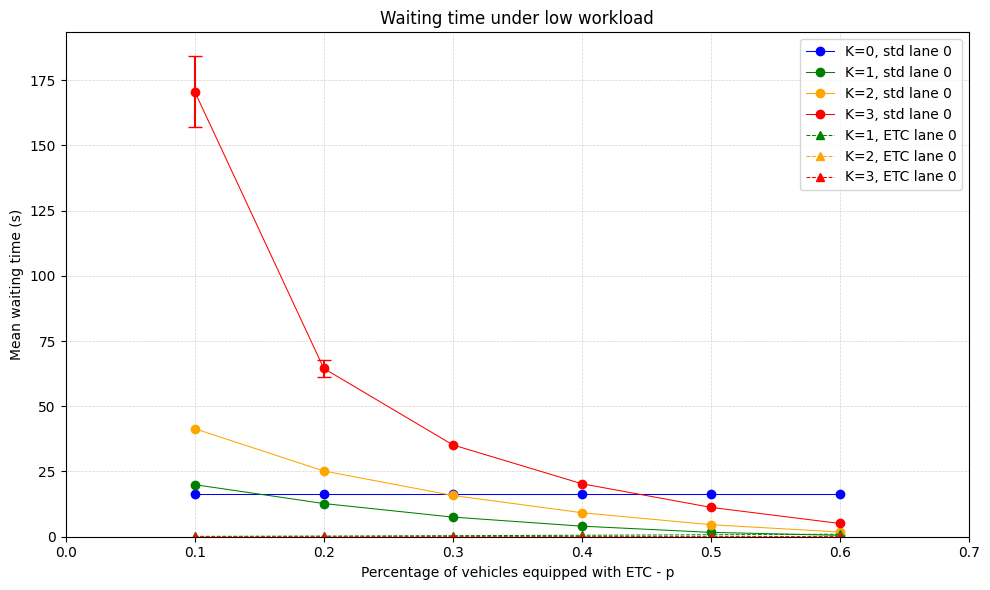

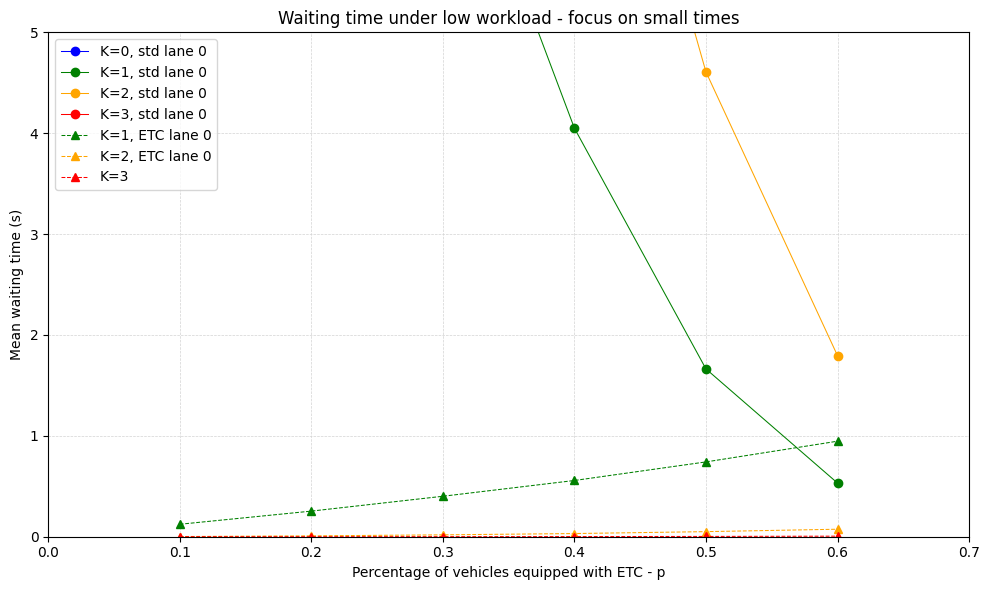

In [335]:
plt.figure(figsize=(10, 6))

# Add the plots

PlotData(plt, stdl_wai, color_map, 'solid', "o")
PlotData(plt, etcl_wai, color_map, 'dashed', "^")

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean waiting time (s)")
plt.title("Waiting time under low workload")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0)  # Y axis starts at 0
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
handles, labels = plt.gca().get_legend_handles_labels()
label_count = {}
for i in range(len(labels)):
      label = labels[i]
      
      if label not in label_count: label_count[label] = 1
      else: label_count[label] += 1
      
      # Append std or etc
      if label_count[label] == 1: labels[i] = f'{label}, std lane 0'
      else: labels[i] = f'{label}, ETC lane 0'
plt.legend(handles, labels, loc='upper right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_lowWorkload_waiting'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


## ETC lane only

plt.figure(figsize=(10, 6))

# Add the plots
PlotData(plt, stdl_wai, color_map, 'solid', "o")
PlotData(plt, etcl_wai, color_map, 'dashed', "^")

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean waiting time (s)")
plt.title("Waiting time under low workload - focus on small times")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0, 5)  # Set the Y-axis range
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
handles, labels = plt.gca().get_legend_handles_labels()
label_count = {}
for i in range(len(labels)-1):
      label = labels[i]
      
      if label not in label_count: label_count[label] = 1
      else: label_count[label] += 1
      
      # Append std or etc
      if label_count[label] == 1: labels[i] = f'{label}, std lane 0'
      else: labels[i] = f'{label}, ETC lane 0'
plt.legend(handles, labels, loc='upper left')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_lowWorkload_waiting_etcOnly'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


### Medium workload

In [336]:
stdl_res = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_MEDIUM, STD_LANE_0, 'ResponseTime')
stdl_wai = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_MEDIUM, STD_LANE_0, 'WaitingTime')

mean_service_time = GetParamaterValue(DIST_EXPONENTIAL, WORKLOAD_MEDIUM, MEAN_SERVICE_TIME_STD_LANE)
if mean_service_time.endswith('s'):
      mean_service_time = float(mean_service_time[:-1])
      
etcl_res = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_MEDIUM, ETC_LANE_0, 'ResponseTime')
etcl_wai = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_MEDIUM, ETC_LANE_0, 'WaitingTime')

# Colors for each K
color_map = {
    0: 'blue',
    1: 'green',
    2: 'orange',
    3: 'red'      
}


#### Response time

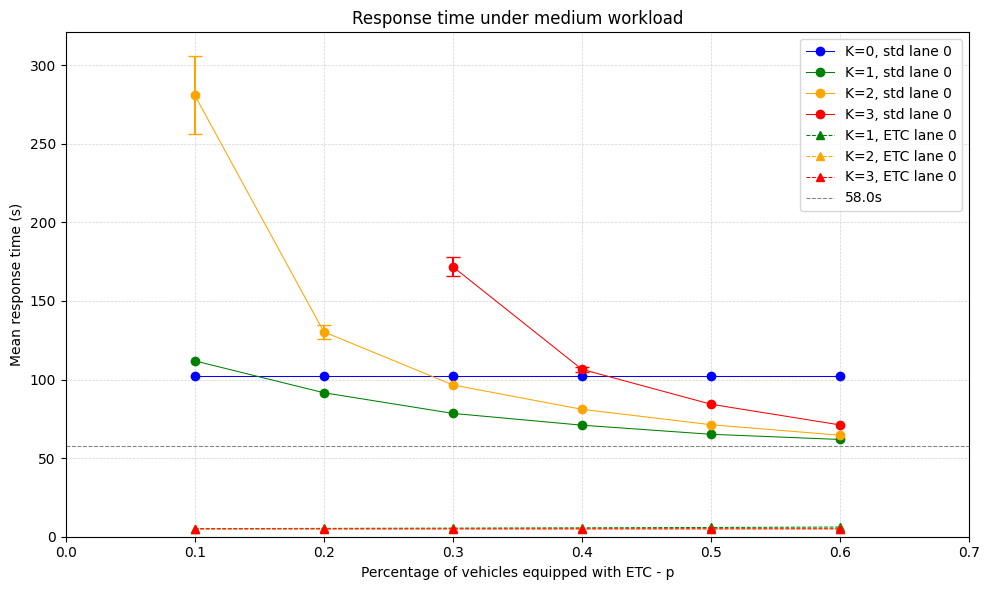

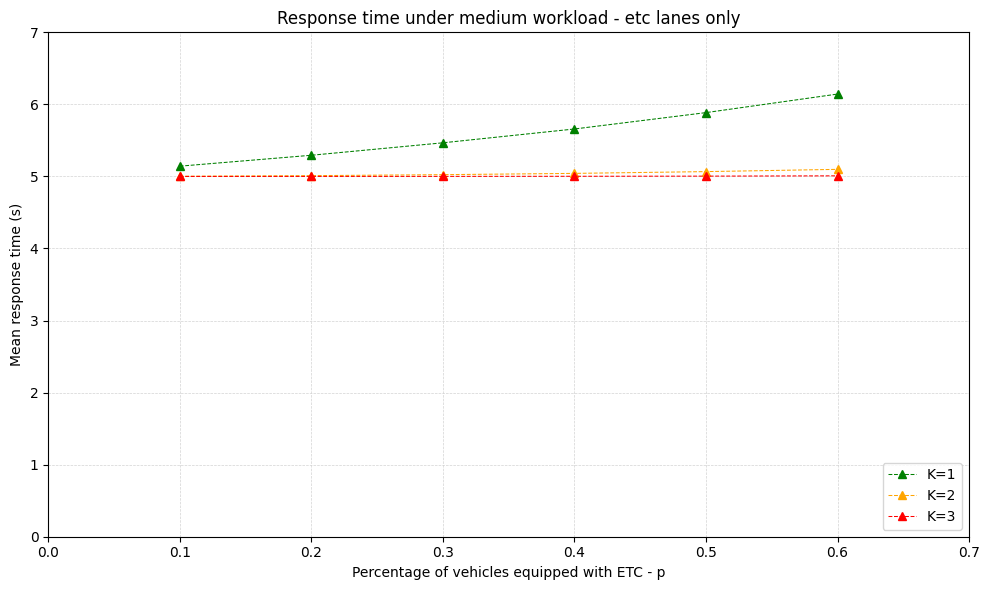

In [337]:
plt.figure(figsize=(10, 6))

# Add the plots
exclusion = {(3, 0.1), (3, 0.2)}
PlotData(plt, stdl_res, color_map, 'solid', "o", exclusion)
PlotData(plt, etcl_res, color_map, 'dashed', "^")

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean response time (s)")
plt.title("Response time under medium workload")

# Horizontal line for the mean service time of the standard lanes
plt.axhline(y=mean_service_time, color='grey', linestyle='--', linewidth = 0.75, label=f"{mean_service_time}s")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0)  # Y axis starts at 0
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
handles, labels = plt.gca().get_legend_handles_labels()
label_count = {}
for i in range(len(labels)-1):
      label = labels[i]
      
      if label not in label_count: label_count[label] = 1
      else: label_count[label] += 1
      
      # Append std or etc
      if label_count[label] == 1: labels[i] = f'{label}, std lane 0'
      else: labels[i] = f'{label}, ETC lane 0'
plt.legend(handles, labels, loc='upper right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_medWorkload_response'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


## ETC lane only

plt.figure(figsize=(10, 6))

# Add the plots
PlotData(plt, etcl_res, color_map, 'dashed', "^")

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean response time (s)")
plt.title("Response time under medium workload - etc lanes only")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0, 7)  # Set the Y-axis range
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
plt.legend(loc='lower right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_medWorkload_response_etcOnly'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


#### Waiting time

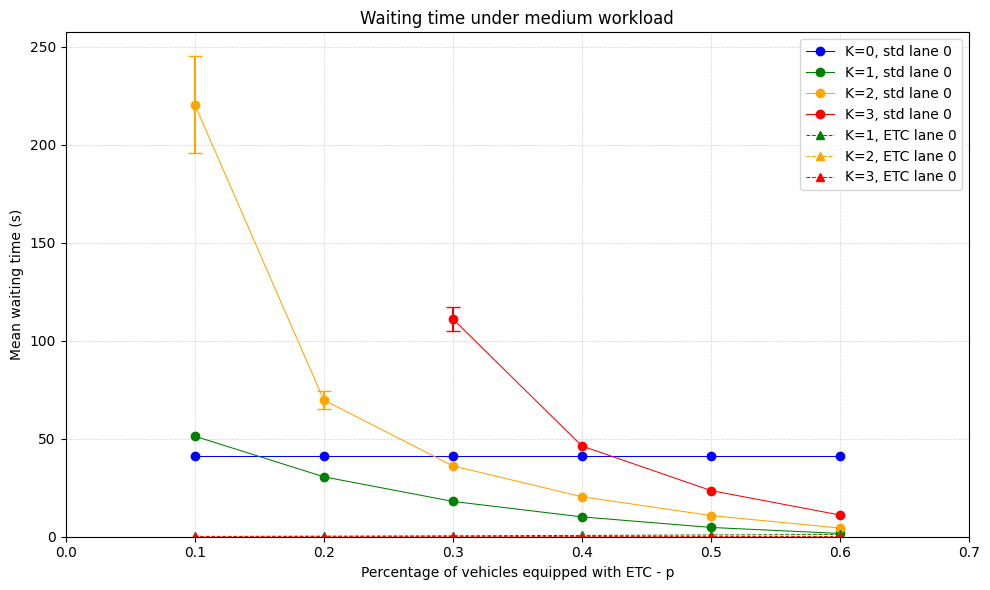

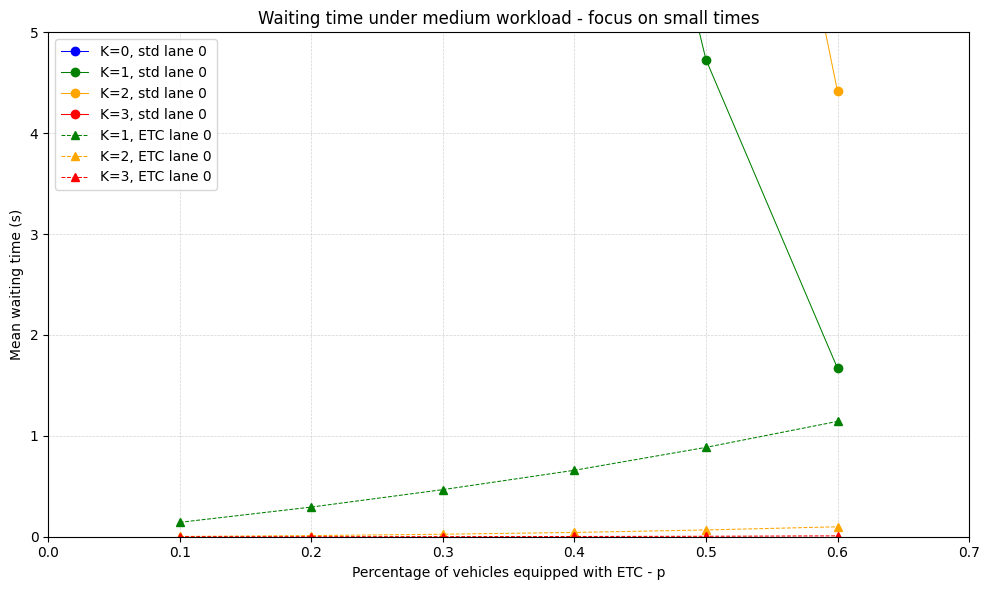

In [338]:
plt.figure(figsize=(10, 6))

# Add the plots
exclusion = {(3, 0.1), (3, 0.2)}
PlotData(plt, stdl_wai, color_map, 'solid', "o", exclusion)
PlotData(plt, etcl_wai, color_map, 'dashed', "^")

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean waiting time (s)")
plt.title("Waiting time under medium workload")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0)  # Y axis starts at 0
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
handles, labels = plt.gca().get_legend_handles_labels()
label_count = {}
for i in range(len(labels)):
      label = labels[i]
      
      if label not in label_count: label_count[label] = 1
      else: label_count[label] += 1
      
      # Append std or etc
      if label_count[label] == 1: labels[i] = f'{label}, std lane 0'
      else: labels[i] = f'{label}, ETC lane 0'
plt.legend(handles, labels, loc='upper right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_medWorkload_waiting'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


## ETC lane only

plt.figure(figsize=(10, 6))

# Add the plots
PlotData(plt, stdl_wai, color_map, 'solid', "o", exclusion)
PlotData(plt, etcl_wai, color_map, 'dashed', "^")

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean waiting time (s)")
plt.title("Waiting time under medium workload - focus on small times")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0, 5)  # Set the Y-axis range
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
handles, labels = plt.gca().get_legend_handles_labels()
label_count = {}
for i in range(len(labels)):
      label = labels[i]
      
      if label not in label_count: label_count[label] = 1
      else: label_count[label] += 1
      
      # Append std or etc
      if label_count[label] == 1: labels[i] = f'{label}, std lane 0'
      else: labels[i] = f'{label}, ETC lane 0'
plt.legend(handles, labels, loc='upper left')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_medWorkload_waiting_etcOnly'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


### High workload

In [339]:
stdl_res = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_HIGH, STD_LANE_0, 'ResponseTime')
stdl_wai = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_HIGH, STD_LANE_0, 'WaitingTime')

mean_service_time = GetParamaterValue(DIST_EXPONENTIAL, WORKLOAD_HIGH, MEAN_SERVICE_TIME_STD_LANE)
if mean_service_time.endswith('s'):
      mean_service_time = float(mean_service_time[:-1])
      
etcl_res = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_HIGH, ETC_LANE_0, 'ResponseTime')
etcl_wai = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_HIGH, ETC_LANE_0, 'WaitingTime')

# Colors for each K
color_map = {
    0: 'blue',
    1: 'green',
    2: 'orange',
    3: 'red'      
}

#### Response Time

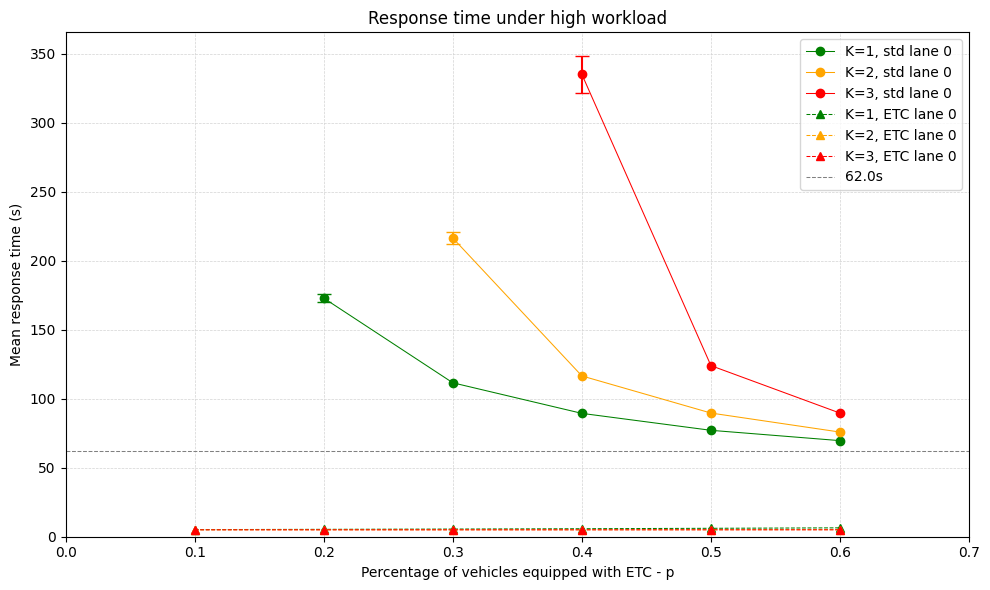

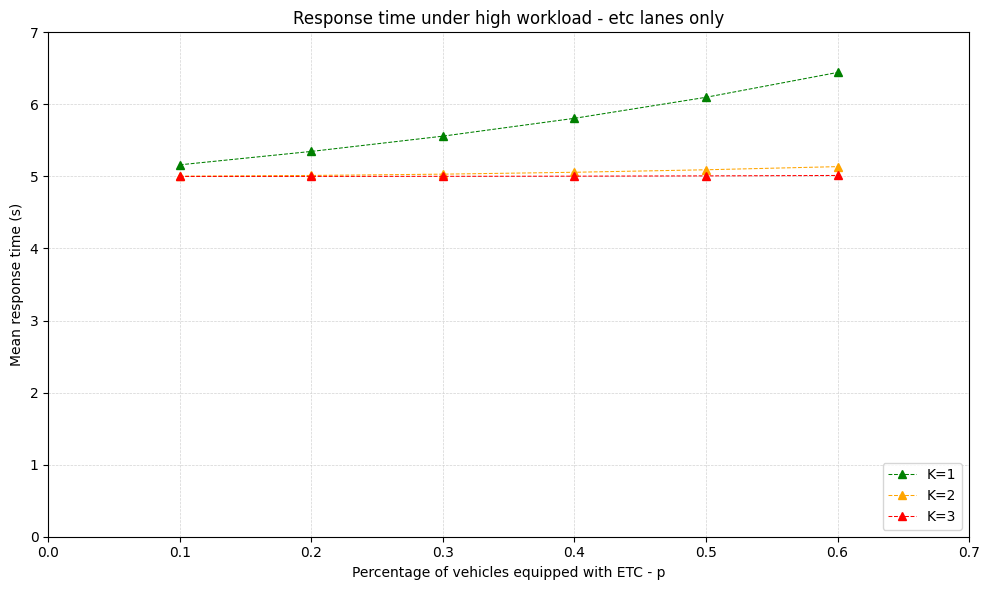

In [340]:
plt.figure(figsize=(10, 6))

# Add the plots
exclusion = {
      (3, 0.1), (3, 0.2), (3, 0.3),
      (2, 0.1), (2, 0.2),
      (1, 0.1), 
      (0,0.1),(0,0.2),(0,0.3),(0,0.4),(0,0.5),(0,0.6)
}
PlotData(plt, stdl_res, color_map, 'solid', "o", exclusion)
PlotData(plt, etcl_res, color_map, 'dashed', "^")

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean response time (s)")
plt.title("Response time under high workload")

# Horizontal line for the mean service time of the standard lanes
plt.axhline(y=mean_service_time, color='grey', linestyle='--', linewidth = 0.75, label=f"{mean_service_time}s")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0)  # Y axis starts at 0
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
handles, labels = plt.gca().get_legend_handles_labels()
handles = handles[1:]
labels = labels[1:]
label_count = {}
#labels = labels[1:]
for i in range(len(labels)-1):
      label = labels[i]
      
      if label not in label_count: label_count[label] = 1
      else: label_count[label] += 1
      
      # Append std or etc
      if label_count[label] == 1: labels[i] = f'{label}, std lane 0'
      else: labels[i] = f'{label}, ETC lane 0'
plt.legend(handles, labels, loc='upper right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_highWorkload_response'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


## ETC lane only

plt.figure(figsize=(10, 6))

# Add the plots
PlotData(plt, etcl_res, color_map, 'dashed', "^")

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean response time (s)")
plt.title("Response time under high workload - etc lanes only")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0, 7)  # Set the Y-axis range
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
plt.legend(loc='lower right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_highWorkload_response_etcOnly'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


#### Waiting time

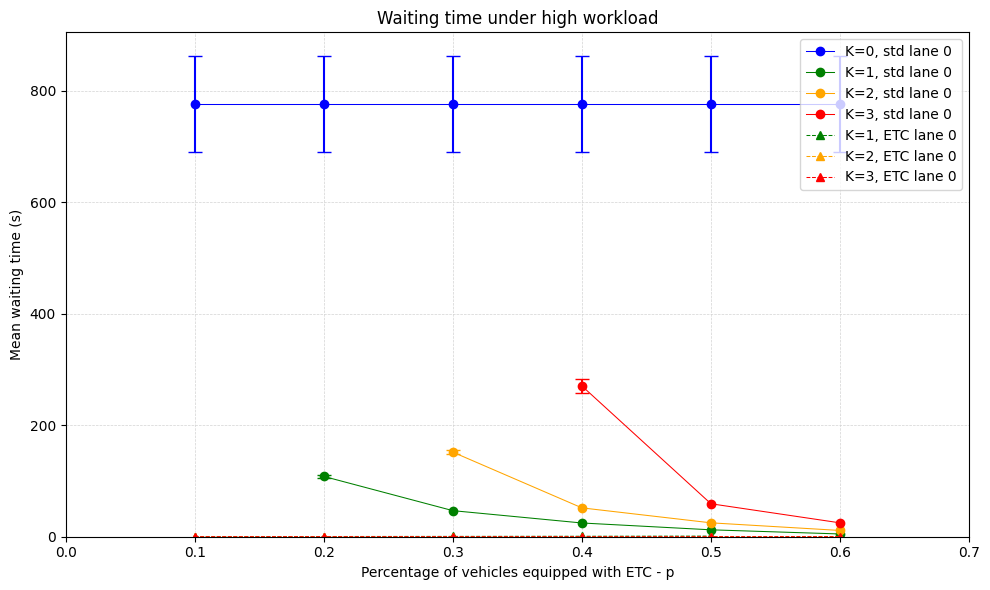

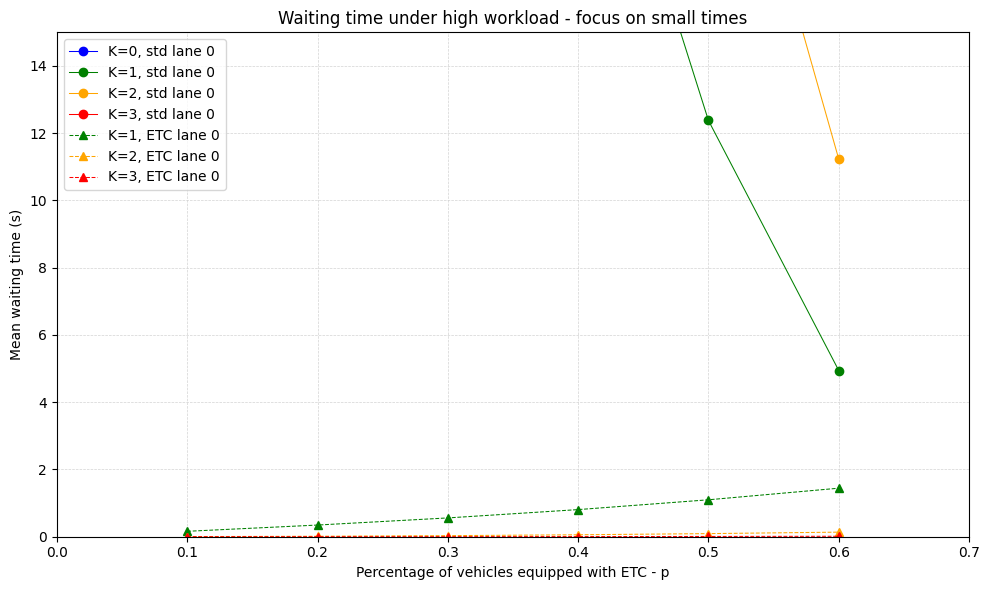

In [341]:
plt.figure(figsize=(10, 6))

# Add the plots
exclusion = {
      (3, 0.1), (3, 0.2), (3, 0.3),
      (2, 0.1), (2, 0.2),
      (1, 0.1)
}
PlotData(plt, stdl_wai, color_map, 'solid', "o", exclusion)
exclusion = {
      (1, 0.6)
}
PlotData(plt, etcl_wai, color_map, 'dashed', "^", exclusion)

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean waiting time (s)")
plt.title("Waiting time under high workload")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0)  # Y axis starts at 0
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
handles, labels = plt.gca().get_legend_handles_labels()
label_count = {}
for i in range(len(labels)):
      label = labels[i]
      
      if label not in label_count: label_count[label] = 1
      else: label_count[label] += 1
      
      # Append std or etc
      if label_count[label] == 1: labels[i] = f'{label}, std lane 0'
      else: labels[i] = f'{label}, ETC lane 0'
plt.legend(handles, labels, loc='upper right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_highWorkload_waiting'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


## ETC lane only

plt.figure(figsize=(10, 6))

# Add the plots
PlotData(plt, stdl_wai, color_map, 'solid', "o")
PlotData(plt, etcl_wai, color_map, 'dashed', "^")

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean waiting time (s)")
plt.title("Waiting time under high workload - focus on small times")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0, 15)  # Set the Y-axis range
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
handles, labels = plt.gca().get_legend_handles_labels()
label_count = {}
for i in range(len(labels)):
      label = labels[i]
      
      if label not in label_count: label_count[label] = 1
      else: label_count[label] += 1
      
      # Append std or etc
      if label_count[label] == 1: labels[i] = f'{label}, std lane 0'
      else: labels[i] = f'{label}, ETC lane 0'
plt.legend(handles, labels, loc='upper left')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_highWorkload_waiting_etcOnly'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


### 24 Lanes, High workload

In [342]:
stdl_res = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_HIGH_24_LANES, STD_LANE_0, 'ResponseTime')
stdl_wai = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_HIGH_24_LANES, STD_LANE_0, 'WaitingTime')

mean_service_time = GetParamaterValue(DIST_EXPONENTIAL, WORKLOAD_HIGH_24_LANES, MEAN_SERVICE_TIME_STD_LANE)
if mean_service_time.endswith('s'):
      mean_service_time = float(mean_service_time[:-1])
      
etcl_res = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_HIGH_24_LANES, ETC_LANE_0, 'ResponseTime')
etcl_wai = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_HIGH_24_LANES, ETC_LANE_0, 'WaitingTime')

# Colors for each K
color_map = {
    1: 'green',
    2: 'orange',
    3: 'red'      
}

#### Response Time

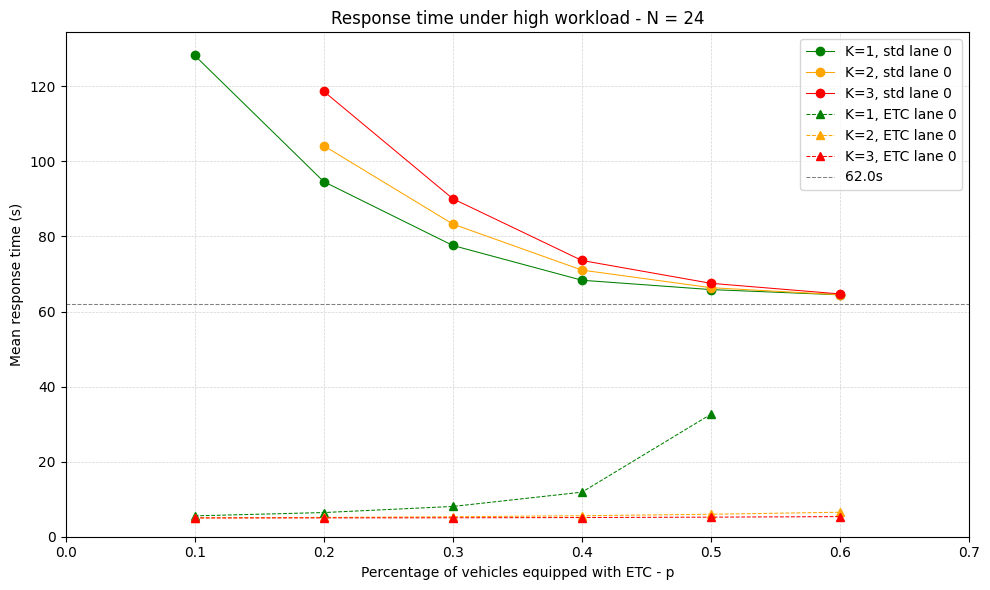

In [ ]:
plt.figure(figsize=(10, 6))

# Add the plots
exclusion = {
      (3, 0.1),
      (2, 0.1),
}
PlotData(plt, stdl_res, color_map, 'solid', "o", exclusion)
exclusion = {
      (1, 0.6)
}
PlotData(plt, etcl_res, color_map, 'dashed', "^", exclusion)

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean response time (s)")
plt.title("Response time under high workload - N = 24")

# Horizontal line for the mean service time of the standard lanes
plt.axhline(y=mean_service_time, color='grey', linestyle='--', linewidth = 0.75, label=f"{mean_service_time}s")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0)  # Y axis starts at 0
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
handles, labels = plt.gca().get_legend_handles_labels()
label_count = {}
for i in range(len(labels)-1):
      label = labels[i]
      
      if label not in label_count: label_count[label] = 1
      else: label_count[label] += 1
      
      # Append std or etc
      if label_count[label] == 1: labels[i] = f'{label}, std lane 0'
      else: labels[i] = f'{label}, ETC lane 0'
plt.legend(handles, labels, loc='upper right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_N24_highWorkload_response'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


## ETC lane only

plt.figure(figsize=(10, 6))

# Add the plots
PlotData(plt, etcl_res, color_map, 'dashed', "^")

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean response time (s)")
plt.title("Response time under high workload - N = 24 - etc lanes only")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0, 20)  # Set the Y-axis range
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
plt.legend(loc='lower right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_N24_highWorkload_response_etcOnly'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


#### Waiting Time

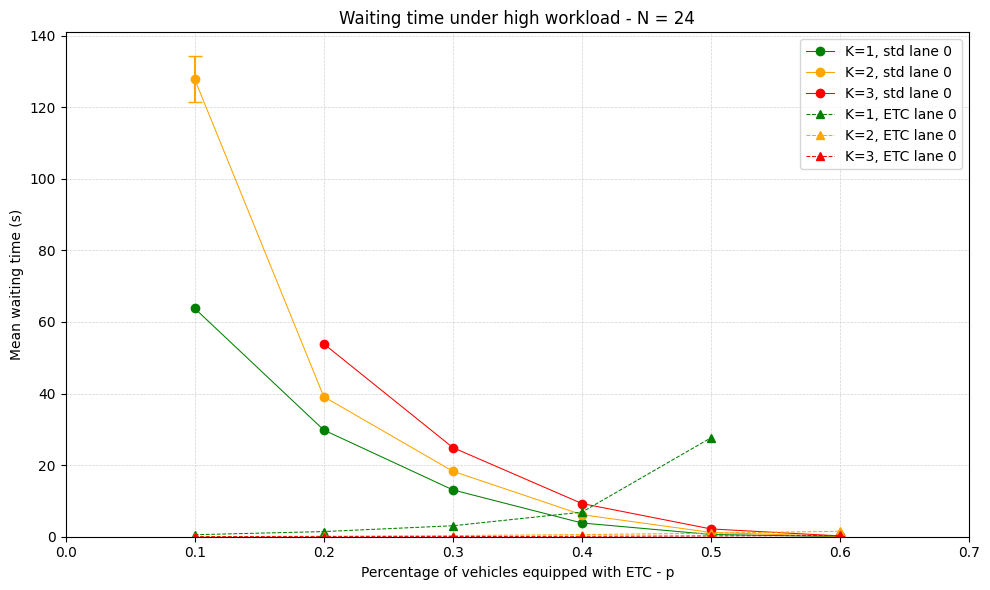

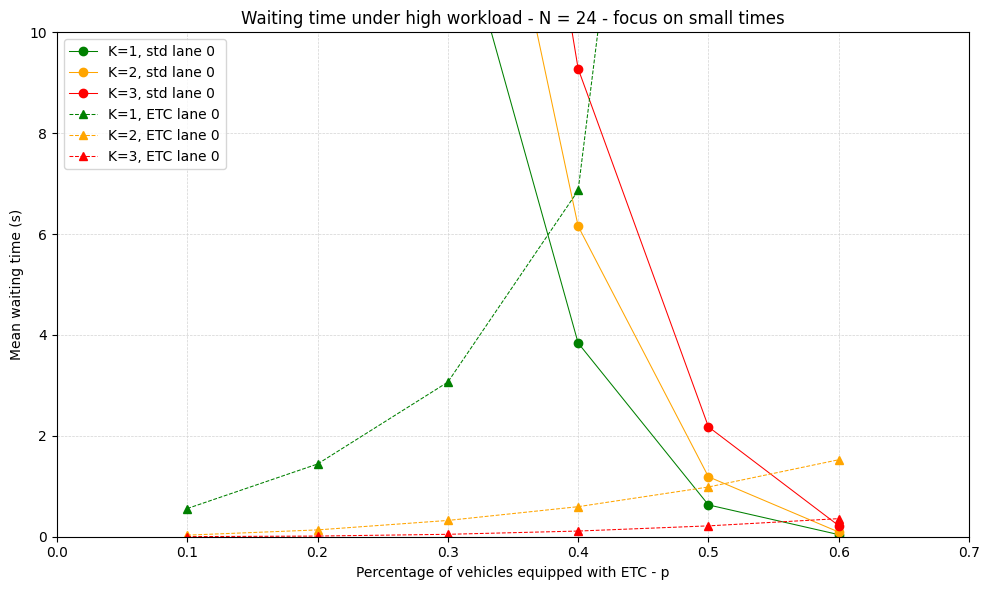

In [ ]:
plt.figure(figsize=(10, 6))

# Add the plots
exclusion = {
      (3, 0.1),
      # (2, 0.1),
}
PlotData(plt, stdl_wai, color_map, 'solid', "o", exclusion)
exclusion = {
      (1, 0.6)
}
PlotData(plt, etcl_wai, color_map, 'dashed', "^", exclusion)

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean waiting time (s)")
plt.title("Waiting time under high workload - N = 24")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0)  # Y axis starts at 0
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
handles, labels = plt.gca().get_legend_handles_labels()
label_count = {}
for i in range(len(labels)):
      label = labels[i]
      
      if label not in label_count: label_count[label] = 1
      else: label_count[label] += 1
      
      # Append std or etc
      if label_count[label] == 1: labels[i] = f'{label}, std lane 0'
      else: labels[i] = f'{label}, ETC lane 0'
plt.legend(handles, labels, loc='upper right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_N24_highWorkload_waiting'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


## ETC lane only

plt.figure(figsize=(10, 6))

# Add the plots
PlotData(plt, stdl_wai, color_map, 'solid', "o")
PlotData(plt, etcl_wai, color_map, 'dashed', "^")

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean waiting time (s)")
plt.title("Waiting time under high workload - N = 24 - focus on small times")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0, 10)  # Set the Y-axis range
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
handles, labels = plt.gca().get_legend_handles_labels()
label_count = {}
for i in range(len(labels)):
      label = labels[i]
      
      if label not in label_count: label_count[label] = 1
      else: label_count[label] += 1
      
      # Append std or etc
      if label_count[label] == 1: labels[i] = f'{label}, std lane 0'
      else: labels[i] = f'{label}, ETC lane 0'
plt.legend(handles, labels, loc='upper left')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_N24_highWorkload_waiting_etcOnly'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


### 100 Lanes, High Workload

In [316]:
stdl_res = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_HIGH_100_LANES, STD_LANE_0, 'ResponseTime')
stdl_wai = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_HIGH_100_LANES, STD_LANE_0, 'WaitingTime')

mean_service_time = GetParamaterValue(DIST_EXPONENTIAL, WORKLOAD_HIGH_100_LANES, MEAN_SERVICE_TIME_STD_LANE)
if mean_service_time.endswith('s'):
      mean_service_time = float(mean_service_time[:-1])
      
etcl_res = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_HIGH_100_LANES, ETC_LANE_0, 'ResponseTime')
etcl_wai = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_HIGH_100_LANES, ETC_LANE_0, 'WaitingTime')

# Colors for each K
color_map = {
    1: 'red',
    2: 'orange',
    3: 'gold',
    4: 'lime',
    5: 'green',
    6: 'cyan',
    7: 'blue',
    8: 'indigo',
    9: 'violet',
    10: 'pink'
}

#### Response Time

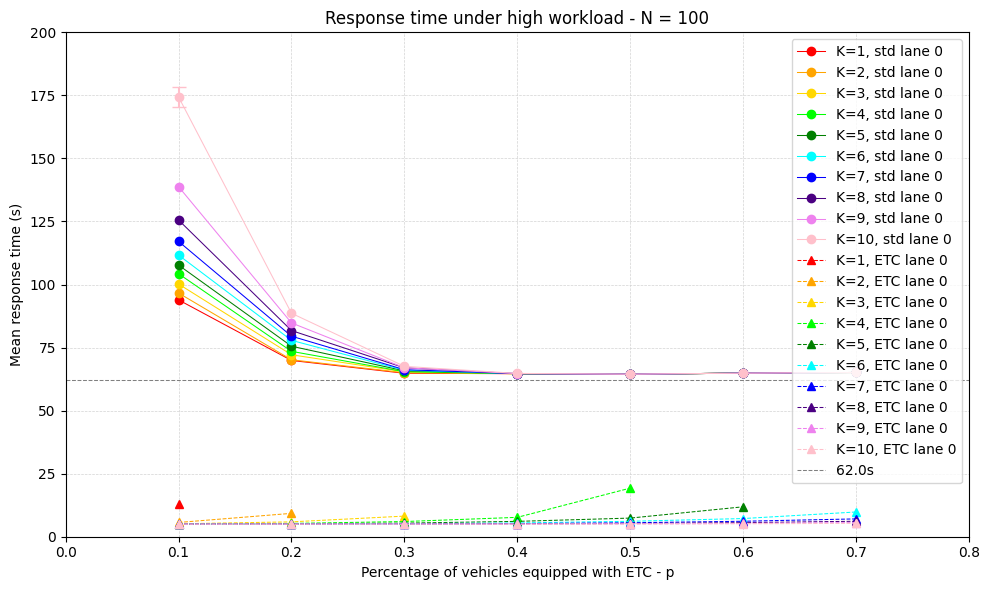

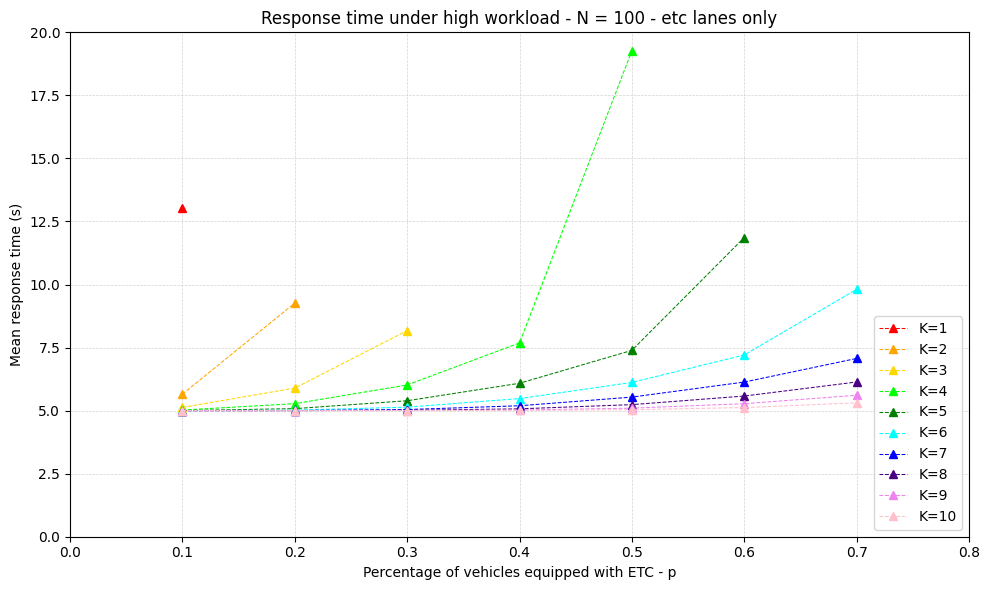

In [ ]:
plt.figure(figsize=(10, 6))

# Add the plots
exclusion = {
}
PlotData(plt, stdl_res, color_map, 'solid', "o", exclusion)
exclusion = {
      (1, 0.2), (1, 0.3), (1, 0.4), (1, 0.5), (1, 0.6), (1, 0.7),
      (2, 0.3), (2, 0.4), (2, 0.5), (2, 0.6), (2, 0.7),
      (3, 0.4), (3, 0.5), (3, 0.6), (3, 0.7),
      (4, 0.6), (4, 0.7),
      (5, 0.7)
}
PlotData(plt, etcl_res, color_map, 'dashed', "^", exclusion)

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean response time (s)")
plt.title("Response time under high workload - N = 100")

# Horizontal line for the mean service time of the standard lanes
plt.axhline(y=mean_service_time, color='grey', linestyle='--', linewidth = 0.75, label=f"{mean_service_time}s")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.9, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.9, 0.1)])
plt.xlim(0, 0.8)  # Set the X-axis range
plt.ylim(0, 200)  # Y axis starts at 0
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
handles, labels = plt.gca().get_legend_handles_labels()
label_count = {}
for i in range(len(labels)-1):
      label = labels[i]
      
      if label not in label_count: label_count[label] = 1
      else: label_count[label] += 1
      
      # Append std or etc
      if label_count[label] == 1: labels[i] = f'{label}, std lane 0'
      else: labels[i] = f'{label}, ETC lane 0'
plt.legend(handles, labels, loc='upper right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_N100_highWorkload_response'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


## ETC lane only

plt.figure(figsize=(10, 6))

# Add the plots
PlotData(plt, etcl_res, color_map, 'dashed', "^", exclusion)

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean response time (s)")
plt.title("Response time under high workload - N = 100 - etc lanes only")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.9, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.9, 0.1)])
plt.xlim(0, 0.8)  # Set the X-axis range
plt.ylim(0, 20)  # Set the Y-axis range
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
plt.legend(loc='lower right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_N100_highWorkload_response_etcOnly'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


#### Waiting time

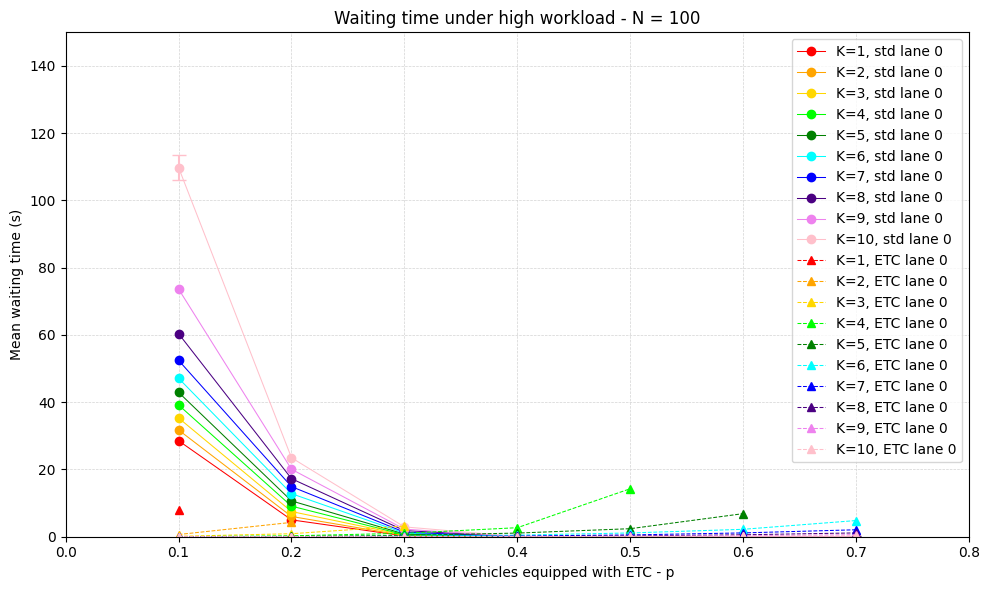

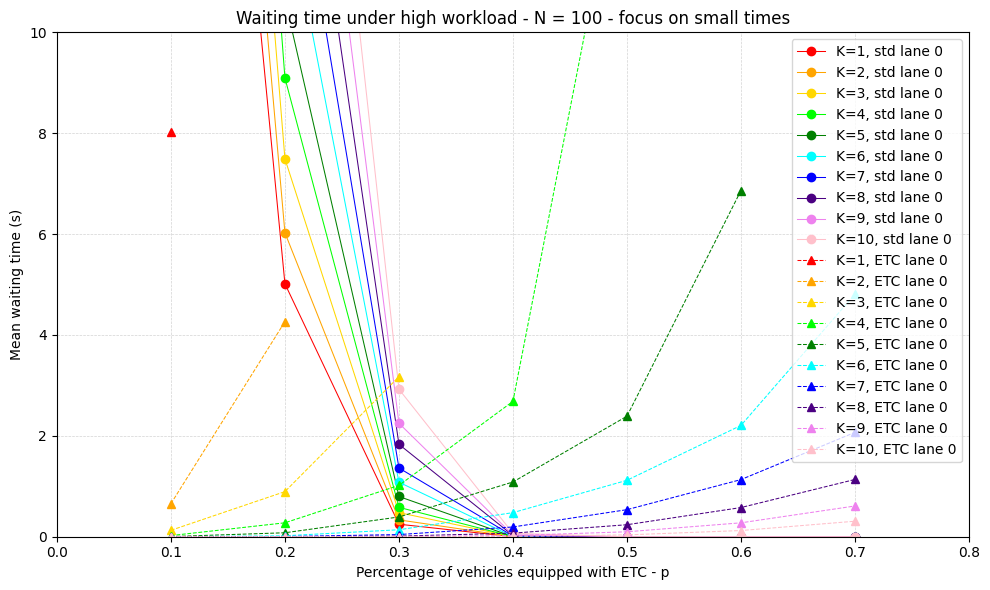

In [ ]:
plt.figure(figsize=(10, 6))

# Add the plots

PlotData(plt, stdl_wai, color_map, 'solid', "o")
PlotData(plt, etcl_wai, color_map, 'dashed', "^", exclusion)

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean waiting time (s)")
plt.title("Waiting time under high workload - N = 100")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.9, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.9, 0.1)])
plt.xlim(0, 0.8)  # Set the X-axis range
plt.ylim(0, 150)  # Y axis starts at 0
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
# Legend
handles, labels = plt.gca().get_legend_handles_labels()
label_count = {}
for i in range(len(labels)):
      label = labels[i]
      
      if label not in label_count: label_count[label] = 1
      else: label_count[label] += 1
      
      # Append std or etc
      if label_count[label] == 1: labels[i] = f'{label}, std lane 0'
      else: labels[i] = f'{label}, ETC lane 0'
plt.legend(handles, labels, loc='upper right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_N100_highWorkload_waiting'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()



plt.figure(figsize=(10, 6))

# Add the plots

PlotData(plt, stdl_wai, color_map, 'solid', "o")
PlotData(plt, etcl_wai, color_map, 'dashed', "^", exclusion)

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean waiting time (s)")
plt.title("Waiting time under high workload - N = 100 - focus on small times")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.9, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.9, 0.1)])
plt.xlim(0, 0.8)  # Set the X-axis range
plt.ylim(0, 10)  # Y axis starts at 0
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
handles, labels = plt.gca().get_legend_handles_labels()
label_count = {}
for i in range(len(labels)):
      label = labels[i]
      
      if label not in label_count: label_count[label] = 1
      else: label_count[label] += 1
      
      # Append std or etc
      if label_count[label] == 1: labels[i] = f'{label}, std lane 0'
      else: labels[i] = f'{label}, ETC lane 0'
plt.legend(handles, labels, loc='upper right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'exp_N100_highWorkload_waiting_etcOnly'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


## LogNormal Distribution

In [319]:
# Response time
stdl_low_res = CollectScalars(DIST_LOGNORMAL, WORKLOAD_LOW, STD_LANE_0, 'ResponseTime')
stdl_med_res = CollectScalars(DIST_LOGNORMAL, WORKLOAD_MEDIUM, STD_LANE_0, 'ResponseTime')
stdl_hig_res = CollectScalars(DIST_LOGNORMAL, WORKLOAD_HIGH, STD_LANE_0, 'ResponseTime')

stdl_exp = CollectScalars(DIST_EXPONENTIAL, WORKLOAD_MEDIUM, STD_LANE_0, 'ResponseTime')

# Waiting times
stdl_low_wai = CollectScalars(DIST_LOGNORMAL, WORKLOAD_LOW, STD_LANE_0, 'WaitingTime')
stdl_med_wai = CollectScalars(DIST_LOGNORMAL, WORKLOAD_MEDIUM, STD_LANE_0, 'WaitingTime')
stdl_hig_wai = CollectScalars(DIST_LOGNORMAL, WORKLOAD_HIGH, STD_LANE_0, 'WaitingTime')

mean_service_time = GetParamaterValue(DIST_EXPONENTIAL, WORKLOAD_HIGH_100_LANES, MEAN_SERVICE_TIME_STD_LANE)
if mean_service_time.endswith('s'):
      mean_service_time = float(mean_service_time[:-1])

# Colors for each K
color_map = {
    1: 'green',
    2: 'orange',
    3: 'red'      
}

#### Response Time

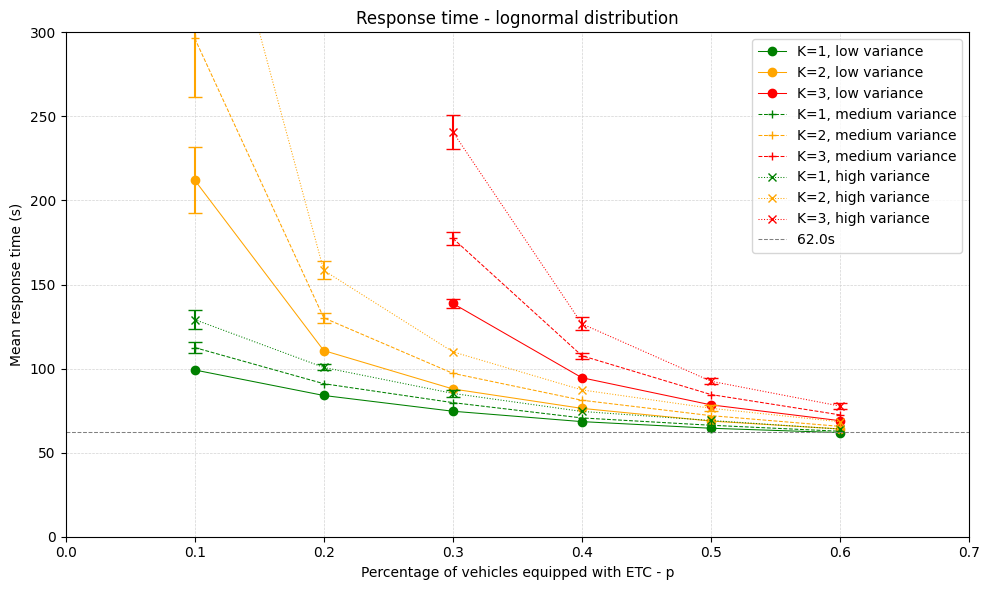

In [ ]:
plt.figure(figsize=(10, 6))

# Add the plots
exclusion = {
      (3, 0.1), (3, 0.2)
}
PlotData(plt, stdl_low_res, color_map, 'solid', "o", exclusion)
PlotData(plt, stdl_med_res, color_map, 'dashed', "+", exclusion)
PlotData(plt, stdl_hig_res, color_map, 'dotted', "x", exclusion)
exclusion = {
      (1, 0.2), (1, 0.3), (1, 0.4), (1, 0.5), (1, 0.6), (1, 0.7),
      (2, 0.3), (2, 0.4), (2, 0.5), (2, 0.6), (2, 0.7),
      (3, 0.4), (3, 0.5), (3, 0.6), (3, 0.7),
      (4, 0.6), (4, 0.7),
      (5, 0.7)
}

# Chart configuration
plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean response time (s)")
plt.title("Response time - lognormal distribution")

# Horizontal line for the mean service time of the standard lanes
plt.axhline(y=mean_service_time, color='grey', linestyle='--', linewidth = 0.75, label=f"{mean_service_time}s")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0, 300)  # Y axis starts at 0
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
handles, labels = plt.gca().get_legend_handles_labels()
label_count = {}
for i in range(len(labels)-1):
      label = labels[i]
      
      if label not in label_count: label_count[label] = 1
      else: label_count[label] += 1
      
      # Append std or etc
      if label_count[label] == 1: labels[i] = f'{label}, low variance'
      elif label_count[label] == 2: labels[i] = f'{label}, medium variance'
      else: labels[i] = f'{label}, high variance'
plt.legend(handles, labels, loc='upper right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'lognormal_reponse_time'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


#### Waiting time

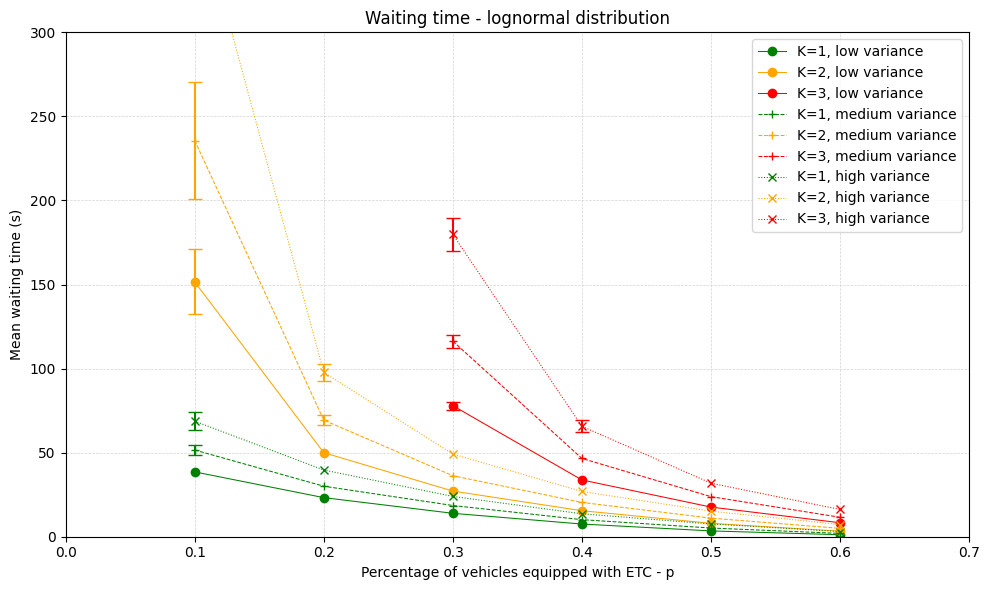

In [ ]:
plt.figure(figsize=(10, 6))

# Add the plots
exclusion = {
      (3, 0.1), (3, 0.2)
}
PlotData(plt, stdl_low_wai, color_map, 'solid', "o", exclusion)
PlotData(plt, stdl_med_wai, color_map, 'dashed', "+", exclusion)
PlotData(plt, stdl_hig_wai, color_map, 'dotted', "x", exclusion)
exclusion = {
      (1, 0.2), (1, 0.3), (1, 0.4), (1, 0.5), (1, 0.6), (1, 0.7),
      (2, 0.3), (2, 0.4), (2, 0.5), (2, 0.6), (2, 0.7),
      (3, 0.4), (3, 0.5), (3, 0.6), (3, 0.7),
      (4, 0.6), (4, 0.7),
      (5, 0.7)
}

# Chart configuration

plt.xlabel("Percentage of vehicles equipped with ETC - p")
plt.ylabel("Mean waiting time (s)")
plt.title("Waiting time - lognormal distribution")

# Set X-axis ticks every 0.1 from 0 to 0.7
plt.xticks(np.arange(0, 0.8, 0.1), labels=[f'{i:.1f}' for i in np.arange(0, 0.8, 0.1)])
plt.xlim(0, 0.7)  # Set the X-axis range
plt.ylim(0, 300)  # Y axis starts at 0
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Legend
handles, labels = plt.gca().get_legend_handles_labels()
label_count = {}
for i in range(len(labels)):
      label = labels[i]
      
      if label not in label_count: label_count[label] = 1
      else: label_count[label] += 1
      
      # Append std or etc
      if label_count[label] == 1: labels[i] = f'{label}, low variance'
      elif label_count[label] == 2: labels[i] = f'{label}, medium variance'
      else: labels[i] = f'{label}, high variance'
plt.legend(handles, labels, loc='upper right')

# Show the chart
plt.tight_layout()
if SAVE_GRAPH_FILES:
      fileName = 'lognormal_waiting_time'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()
